# Daten laden und aufbereiten: von der Rohmatrix zur Analysematrix

In diesem Notebook laden wir die Daten des TCGA PanCanAtlas (*The Cancer Genome Atlas*, Pan-Cancer Atlas), stellen die Metadaten zu Genen und Proben zusammen
und setzen die Entscheidungen aus `datenaufbereitung.md` um. Was in den Daten steckt (Herkunft, Gene, Proben, gemessene Werte, Batch-Effekte), erklärt `datenaufbereitung.md`. Ergebnis ist **eine fertige Matrix**, die alle folgenden Notebooks
(Hauptkomponentenanalyse, UMAP (*Uniform Manifold Approximation and Projection*), Clustering) gemeinsam verwenden.

Die ganze Aufbereitung steckt in **einer Funktion mit Parametern**. Robustheitsprüfungen ändern nur Parameter, nicht den Code.
Die Kürzel A1, B1, … verweisen auf die Entscheidungen in `datenaufbereitung.md`.

Einige Vorschläge lauteten „erst prüfen“. Diese Prüfungen stehen in den Abschnitten 5 bis 9; ihr Ergebnis bestimmt die endgültigen Parameter.

**Voraussetzung:** keine. Beim ersten Ausführen lädt das Notebook die Daten (etwa 1,9 Gigabyte) automatisch nach `data/pancanatlas/`.

## Aufbau

1. Daten herunterladen und einlesen
2. Metadaten der Gene und Proben
3. Die Aufbereitung als Funktion
4. Geschlechtsgene bestimmen (D3)
5. Der Standardlauf
6. Prüfung: fehlende Werte (B1)
7. Prüfung: Störgrößen und Batch-Effekte (E2)
8. Prüfung: Proben vom älteren Illumina Genome Analyzer (A4)
9. Prüfung: auffällige Proben (A5) und ausgeglichene Stichprobe (A7)
10. Speichern
11. Zusammenfassung

In [1]:
import json
from pathlib import Path

import numpy as np
import requests
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_colwidth", 120)
DATA_DIR = Path("data/pancanatlas")
SEED = 0

## 1. Daten herunterladen und einlesen

Wir brauchen drei Dateien von der PanCanAtlas-Seite der GDC (*Genomic Data Commons*), frei zugänglich und ohne Login:

| Datei | Inhalt |
|---|---|
| `EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv` | Genexpression, eine Zeile pro Gen, eine Spalte pro Probe (1,9 Gigabyte) |
| `TCGA-CDR-SupplementalTableS1.xlsx` | klinische Daten pro Patient (Clinical Data Resource): Tumortyp, Geschlecht, Alter, histologischer Typ |
| `merged_sample_quality_annotations.tsv` | Qualitätsangaben pro Probe: Sequenziergerät, `Do_not_use` („nicht verwenden“) |

Fehlen die Dateien in `data/pancanatlas/`, lädt die nächste Zelle sie über die Programmierschnittstelle der GDC herunter (die lange Zeichenfolge ist die feste Datei-Kennung).
Vorhandene Dateien werden nicht erneut geladen.

In [2]:
TSV = DATA_DIR / "EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv"
CDR_XLSX = DATA_DIR / "TCGA-CDR-SupplementalTableS1.xlsx"
QUALITY_TSV = DATA_DIR / "merged_sample_quality_annotations.tsv"
GDC_FILES = {
    TSV: "https://api.gdc.cancer.gov/data/3586c0da-64d0-4b74-a449-5ff4d9136611",
    CDR_XLSX: "https://api.gdc.cancer.gov/data/1b5f413e-a8d1-4d10-92eb-7c4ae739ed81",
    QUALITY_TSV: "https://api.gdc.cancer.gov/data/1a7d7be8-675d-4e60-a105-19d4121bdebf",
}

def download(url, path, chunk=1 << 20):
    tmp = path.with_suffix(path.suffix + ".part")       # erst fertig geladen umbenennen, damit kein halber Download liegen bleibt
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for block in r.iter_content(chunk):
                f.write(block)
    tmp.rename(path)

DATA_DIR.mkdir(parents=True, exist_ok=True)
for path, url in GDC_FILES.items():
    if not path.exists():
        print("Lade", path.name, "…")
        download(url, path)
    print(f"{path.name}: {path.stat().st_size / 1e6:,.1f} Megabyte")

EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv: 1,882.5 Megabyte
TCGA-CDR-SupplementalTableS1.xlsx: 2.9 Megabyte
merged_sample_quality_annotations.tsv: 8.5 Megabyte


Das Einlesen der Textdatei dauert gut eine Minute. Wir lesen sie deshalb **einmal** ein, drehen sie in die übliche Form **Proben $\times$ Gene**
und speichern sie als NumPy-Binärdatei mit 32-Bit-Gleitkommazahlen (`float32`, etwa 0,9 Gigabyte). Danach lädt sie in Sekunden.
Die Werte sind die Originalwerte: normalisiert auf das obere Quartil, batch-korrigiert, nicht logarithmiert, mit fehlenden und negativen Werten (siehe `datenaufbereitung.md`, Abschnitt 1.5).

In [3]:
NPY = DATA_DIR / "geneExp_samples_x_genes.npy"
GENES_CSV = DATA_DIR / "geneExp_genes.csv"
SAMPLES_CSV = DATA_DIR / "geneExp_samples.csv"
if not NPY.exists():
    df = pd.read_csv(TSV, sep="\t", index_col=0, engine="pyarrow")
    np.save(NPY, df.to_numpy(np.float32).T)
    pd.Series(df.index, name="gene_id").to_csv(GENES_CSV, index=False)
    pd.Series(df.columns, name="barcode").to_csv(SAMPLES_CSV, index=False)
    del df

X_all = np.load(NPY)
gene_id = pd.read_csv(GENES_CSV)["gene_id"]
barcode = pd.read_csv(SAMPLES_CSV)["barcode"]
nan_all = np.isnan(X_all)
print(f"{X_all.shape[0]} Proben × {X_all.shape[1]} Gene, {X_all.nbytes / 1e9:.2f} Gigabyte im Speicher")
print(f"fehlende Werte (NaN): {nan_all.mean():.1%} der Einträge | negative Werte: {(X_all < 0).sum():,}")

11069 Proben × 20531 Gene, 0.91 Gigabyte im Speicher
fehlende Werte (NaN): 1.7% der Einträge | negative Werte: 1,250,289


## 2. Metadaten der Gene und Proben

**Gene:** Die Kennung hat die Form `Symbol|Entrez-Nummer`, zum Beispiel `TP53|7157`. Als lesbaren Namen nehmen wir das Symbol;
nur bei den 29 Genen ohne Symbol (`?`) und beim doppelten Symbol `SLC35E2` hängen wir die Entrez-Nummer an.

In [4]:
teile = gene_id.str.split("|", expand=True)
genes_all = pd.DataFrame({"gene_id": gene_id, "symbol": teile[0], "entrez": teile[1].astype(int)})
ohne_symbol = genes_all["symbol"] == "?"
doppelt = genes_all["symbol"].duplicated(keep=False) & ~ohne_symbol
genes_all["name"] = np.where(ohne_symbol | doppelt, genes_all["symbol"] + "|" + genes_all["entrez"].astype(str), genes_all["symbol"])
assert genes_all["name"].is_unique
print(f"Gene ohne Symbol: {ohne_symbol.sum()} | doppelte Symbole: {genes_all.loc[doppelt, 'symbol'].unique().tolist()}")

Gene ohne Symbol: 29 | doppelte Symbole: ['SLC35E2']


**Proben:** Der TCGA-Barcode jeder Probe, zum Beispiel `TCGA-OR-A5J1-01A-11R-A29S-07`, enthält Klinik (`OR`), Patient (`TCGA-OR-A5J1`), Probentyp (`01`),
Platte (`A29S`) und Sequenzierzentrum (`07`). Dazu holen wir

- aus der **klinischen Tabelle**: Tumortyp, Geschlecht, Alter (für die 46 Proben ohne Eintrag dort den Tumortyp aus der Qualitätsdatei),
- aus der **Qualitätsdatei**: Sequenziergerät (Illumina HiSeq oder der ältere Illumina Genome Analyzer) und die Markierung `Do_not_use`.

Außerdem berechnen wir pro Probe den **Anteil der Gene mit Wert 0** (negative Werte zählen als 0), ein einfaches Qualitätsmerkmal für Prüfung A5.

In [5]:
teile = barcode.str.split("-", expand=True)
meta_all = pd.DataFrame({
    "barcode": barcode,
    "patient": teile[0] + "-" + teile[1] + "-" + teile[2],
    "tss": teile[1],                       # Klinik (Tissue Source Site)
    "sample_type": teile[3].str[:2],
    "vial": teile[3].str[2],
    "portion": teile[4].str[:2],
    "analyte": teile[4].str[2],
    "plate": teile[5],
    "center": teile[6],
})

cdr = pd.read_excel(CDR_XLSX, sheet_name="TCGA-CDR").drop(columns="Unnamed: 0").set_index("bcr_patient_barcode")
quality = pd.read_csv(QUALITY_TSV, sep="\t")
rna_q = (quality[quality["platform"].isin(["IlluminaHiSeq_RNASeqV2", "IlluminaGA_RNASeqV2"])]
         .sort_values("platform", ascending=False)        # wenige Aliquots stehen bei beiden Geräten: HiSeq bevorzugen
         .drop_duplicates("aliquot_barcode")
         .set_index("aliquot_barcode")
         .reindex(barcode))

meta_all["study"] = meta_all["patient"].map(cdr["type"]).fillna(rna_q["cancer type"].reset_index(drop=True))
meta_all["platform"] = rna_q["platform"].map({"IlluminaHiSeq_RNASeqV2": "HiSeq", "IlluminaGA_RNASeqV2": "GA"}).fillna("ohne Angabe").to_numpy()
meta_all["gender"] = meta_all["patient"].map(cdr["gender"]).map({"FEMALE": "weiblich", "MALE": "männlich"})
meta_all["age"] = meta_all["patient"].map(cdr["age_at_initial_pathologic_diagnosis"])
meta_all["do_not_use"] = rna_q["Do_not_use"].to_numpy()
SAMPLE_TYPES = {"01": "Primärtumor", "02": "Rezidiv", "03": "Primärtumor (Blut)", "05": "Primärtumor (zusätzlich)",
                "06": "Metastase", "07": "Metastase (zusätzlich)", "11": "Normalgewebe"}
meta_all["sample_type_name"] = meta_all["sample_type"].map(SAMPLE_TYPES)
meta_all["zero_frac"] = (X_all <= 0).sum(axis=1) / (~nan_all).sum(axis=1)
del nan_all

assert meta_all["study"].notna().all() and meta_all["study"].nunique() == 33
print(f"Patienten: {meta_all['patient'].nunique()} | Kliniken: {meta_all['tss'].nunique()} | Platten: {meta_all['plate'].nunique()} | "
      f"Tumortypen: {meta_all['study'].nunique()}")
print("Probentypen:", meta_all["sample_type_name"].value_counts().to_dict())
print("Sequenziergerät:", meta_all["platform"].value_counts().to_dict(), "| Do_not_use:", int((meta_all["do_not_use"] == True).sum()))

Patienten: 10274 | Kliniken: 713 | Platten: 241 | Tumortypen: 33
Probentypen: {'Primärtumor': 9706, 'Normalgewebe': 737, 'Metastase': 395, 'Primärtumor (Blut)': 173, 'Rezidiv': 46, 'Primärtumor (zusätzlich)': 11, 'Metastase (zusätzlich)': 1}
Sequenziergerät: {'HiSeq': 10438, 'GA': 598, 'ohne Angabe': 33} | Do_not_use: 184


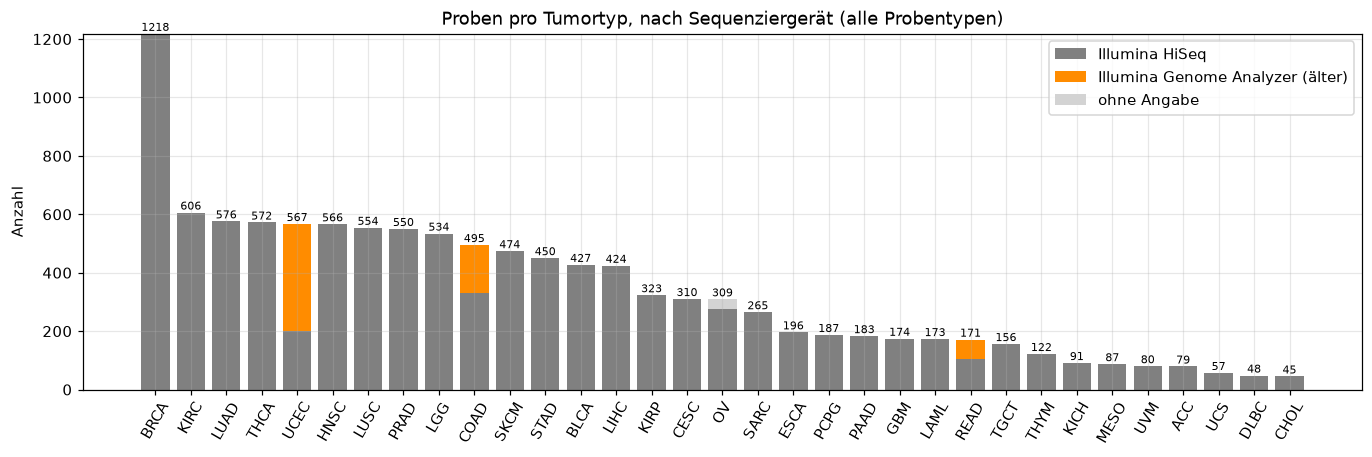

In [6]:
anzahl = meta_all["study"].value_counts()
ct = pd.crosstab(meta_all["study"], meta_all["platform"]).loc[anzahl.index]
fig, ax = plt.subplots(figsize=(15, 4.2))
unten = np.zeros(len(ct))
for spalte, farbe, name in [("HiSeq", "gray", "Illumina HiSeq"), ("GA", "darkorange", "Illumina Genome Analyzer (älter)"), ("ohne Angabe", "lightgray", "ohne Angabe")]:
    ax.bar(ct.index, ct[spalte], bottom=unten, color=farbe, label=name)
    unten += ct[spalte].to_numpy()
for i, v in enumerate(anzahl.to_numpy()):
    ax.text(i, v + 10, str(v), ha="center", fontsize=7)
ax.set(title="Proben pro Tumortyp, nach Sequenziergerät (alle Probentypen)", ylabel="Anzahl")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.show()

**Beobachtungen:**
- Die Tumortypen sind **sehr ungleich groß**: Brustkrebs (BRCA) hat über 1.200 Proben, das diffus großzellige B-Zell-Lymphom (DLBC) und der Gallengangkrebs (CHOL) unter 50.
- Proben vom **älteren Gerät** gibt es nur beim Endometriumkarzinom (UCEC), Dickdarm- (COAD) und Mastdarmkrebs (READ); beim Endometriumkarzinom sind es mehr als die Hälfte.
- Die meisten Proben sind Primärtumoren; dazu kommen Normalgewebe, Metastasen (vor allem beim Melanom der Haut) und Blutproben der akuten myeloischen Leukämie.

Die Tabelle aller 33 Tumortypen mit deutschen Namen steht in `datenaufbereitung.md`, Abschnitt 1.4.

## 3. Die Aufbereitung als Funktion

| Schritt | Entscheidung | Umsetzung | Parameter |
|---|---|---|---|
| 1 | A1 Probentypen | nur Primärtumoren (`01`, bei akuter myeloischer Leukämie `03`) | fest |
| 2 | A3 `Do_not_use` | markierte Proben entfernen; Proben ohne Eintrag in der Qualitätsdatei behalten | fest |
| 3 | A4 Sequenziergerät | nur Illumina HiSeq | `nur_hiseq` |
| 4 | A2 eine Probe pro Patient | erste nach Barcode | fest |
| 5 | A7 Gruppengrößen | optional höchstens $m$ Proben pro Tumortyp (Zufallsstichprobe) | `max_pro_typ` |
| 6 | B1 fehlende Werte | Gene mit fehlenden Werten entfernen (Alternative: mit 0 auffüllen) | `nan_regel` |
| 7 | B2 negative Werte | auf 0 setzen | fest |
| 8 | C1 Log-Transformation | $\log_2(x+1)$ | fest |
| 9 | D1 Expressionsfilter | Gen behalten, wenn es in mindestens einem Tumortyp bei mindestens der Hälfte der Proben $> 0$ ist; Gene mit Varianz 0 entfernen | `min_anteil_exprimiert` |
| 10 | D3 Geschlechtsgene | Liste von Genen entfernen (Abschnitt 4) | `entferne_gene` |
| 11 | D2 Genauswahl | die $k$ Gene mit der größten Varianz (auf der logarithmierten Skala) | `k_gene` |
| 12 | C3, C4 | zentrieren; Standardisieren nur optional | `standardisieren` |

Nicht umgesetzt wird C5 (Proben neu normalisieren) und E1 (zusätzliche Batch-Korrektur): Beides würde die Batch-Korrektur der PanCanAtlas-Autoren teilweise wieder aufheben
bzw. echte Unterschiede zwischen Tumortypen mit entfernen. Batch-Effekte werden stattdessen in Abschnitt 7 kontrolliert.

Die Funktion gibt neben der Matrix ein **Protokoll** zurück: Wie viele Proben und Gene bleiben nach jedem Schritt übrig?

In [7]:
STANDARD = dict(nur_hiseq=True, max_pro_typ=None, nan_regel="gene_entfernen", min_anteil_exprimiert=0.5,
                entferne_gene=(), k_gene=5000, standardisieren=False, seed=SEED)

def aufbereiten(nur_hiseq=True, max_pro_typ=None, nan_regel="gene_entfernen", min_anteil_exprimiert=0.5,
                entferne_gene=(), k_gene=5000, standardisieren=False, seed=SEED):
    # Gibt (Xc, meta, genes, protokoll) zurück; Xc ist zentriert (Proben × Gene, float32), meta und genes passen zu Zeilen bzw. Spalten.
    protokoll = [("alle Proben", len(meta_all), X_all.shape[1])]
    m = meta_all
    sel = m["sample_type"].isin(["01", "03"])                                   # A1
    protokoll.append(("A1 nur Primärtumoren", sel.sum(), X_all.shape[1]))
    sel &= m["do_not_use"].ne(True)                                             # A3 (fehlender Eintrag zählt als verwendbar)
    protokoll.append(("A3 ohne Do_not_use", sel.sum(), X_all.shape[1]))
    if nur_hiseq:                                                               # A4
        sel &= m["platform"].eq("HiSeq")
        protokoll.append(("A4 nur Illumina HiSeq", sel.sum(), X_all.shape[1]))
    idx = m[sel].sort_values("barcode").drop_duplicates("patient").index        # A2
    protokoll.append(("A2 eine Probe pro Patient", len(idx), X_all.shape[1]))
    if max_pro_typ:                                                             # A7
        rng = np.random.default_rng(seed)
        idx = pd.Index(np.concatenate([rng.choice(g.index, min(len(g), max_pro_typ), replace=False)
                                       for _, g in m.loc[idx].groupby("study")]))
        protokoll.append((f"A7 höchstens {max_pro_typ} pro Tumortyp", len(idx), X_all.shape[1]))
    idx = idx.sort_values()
    meta = m.loc[idx].reset_index(drop=True)
    X = X_all[idx]
    genes = genes_all

    if nan_regel == "gene_entfernen":                                           # B1
        ok = ~np.isnan(X).any(axis=0)
        X, genes = X[:, ok], genes[ok]
        protokoll.append(("B1 Gene mit fehlenden Werten entfernt", len(meta), X.shape[1]))
    elif nan_regel == "null":
        X = np.nan_to_num(X, nan=0.0)
        protokoll.append(("B1 fehlende Werte mit 0 aufgefüllt", len(meta), X.shape[1]))
    else:
        raise ValueError(nan_regel)

    L = np.log2(np.clip(X, 0, None) + 1)                                        # B2, C1
    del X
    study = meta["study"].to_numpy()
    anteil = pd.DataFrame(L > 0).groupby(study).mean().max(axis=0).to_numpy()   # D1: bester Tumortyp
    var = L.var(axis=0)
    ok = (anteil >= min_anteil_exprimiert) & (var > 0)
    L, genes, var = L[:, ok], genes[ok], var[ok]
    protokoll.append(("D1 Expressionsfilter", len(meta), L.shape[1]))
    if len(entferne_gene):                                                      # D3
        ok = ~genes["name"].isin(entferne_gene).to_numpy()
        L, genes, var = L[:, ok], genes[ok], var[ok]
        protokoll.append(("D3 Geschlechtsgene entfernt", len(meta), L.shape[1]))
    if k_gene and k_gene < L.shape[1]:                                          # D2
        top = np.sort(np.argsort(var)[::-1][:k_gene])
        L, genes = L[:, top], genes.iloc[top]
        protokoll.append((f"D2 {k_gene} Gene mit größter Varianz", len(meta), L.shape[1]))

    Xc = L - L.mean(axis=0)                                                     # C3
    if standardisieren:                                                         # C4
        Xc = Xc / Xc.std(axis=0, ddof=1)
    protokoll = pd.DataFrame(protokoll, columns=["Schritt", "Proben", "Gene"]).set_index("Schritt")
    return Xc.astype(np.float32), meta, genes.reset_index(drop=True), protokoll

Zwei Hilfsfunktionen, die wir für die Prüfungen mehrfach brauchen:

- `pca`: Hauptkomponentenanalyse über die abgeschnittene Singulärwertzerlegung (wie im Notebook zur Hauptkomponentenanalyse). Gibt die Koordinaten der Proben (*Scores*),
  die Ladungen und den Anteil erklärter Varianz zurück.
- `nachbarn_gleicher_typ`: Für jede Probe die 15 nächsten Nachbarn in den ersten 50 Hauptkomponenten; daraus pro Tumortyp der Anteil der Nachbarn aus **demselben** Tumortyp.
  Das ist unser einfaches Maß dafür, wie klar ein Tumortyp von den anderen abgegrenzt ist (und, umgekehrt, wie stark er anderen ähnelt). Ändert eine Aufbereitungsvariante dieses Maß kaum, ist die Entscheidung für unsere Frage unkritisch.
- `eta2`: Anteil der Varianz einer Größe $y$, der durch eine Gruppierung $g$ erklärt wird: $\eta^2 = \sum_g n_g (\bar y_g - \bar y)^2 \,/\, \sum_i (y_i - \bar y)^2$.
  $\eta^2 = 1$ heißt: Die Gruppen erklären alles; $\eta^2 = 0$: nichts.

In [8]:
def pca(Xc, k=100):
    U, S, Vt = svds(Xc.astype(np.float64), k=k, random_state=SEED)
    o = np.argsort(S)[::-1]
    U, S, Vt = U[:, o], S[o], Vt[o]
    n = Xc.shape[0]
    gesamt = (Xc.astype(np.float64) ** 2).sum() / (n - 1)
    return U * S, Vt, S**2 / (n - 1) / gesamt

def nachbarn(Y, K=15):
    Y = Y.astype(np.float32)
    sq = (Y**2).sum(axis=1)
    nb = np.empty((len(Y), K), dtype=np.int64)
    for s in range(0, len(Y), 2000):                                            # blockweise, um Speicher zu sparen
        d2 = sq[s:s + 2000, None] - 2 * Y[s:s + 2000] @ Y.T + sq[None, :]
        d2[np.arange(d2.shape[0]), np.arange(s, s + d2.shape[0])] = np.inf      # sich selbst ausschließen
        nb[s:s + 2000] = np.argpartition(d2, K, axis=1)[:, :K]
    return nb

def nachbarn_gleicher_typ(Z, meta, n_pc=50, K=15):
    st = meta["study"].to_numpy()
    nb = nachbarn(Z[:, :n_pc], K)
    return pd.Series((st[nb] == st[:, None]).mean(axis=1)).groupby(st).mean()

def eta2(y, g):
    g = pd.Series(np.asarray(g, dtype=object))
    ok = g.notna().to_numpy()
    y, g = np.asarray(y)[ok], g[ok].to_numpy()
    mittel = pd.Series(y).groupby(g).transform("mean").to_numpy()
    return ((mittel - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def innerhalb(y, gruppe):
    # zieht von y den Mittelwert seiner Gruppe ab (z. B. Tumortyp), damit nur die Streuung innerhalb der Gruppen übrig bleibt
    return y - pd.Series(y).groupby(np.asarray(gruppe)).transform("mean").to_numpy()

## 4. Geschlechtsgene bestimmen (D3)

In `datenaufbereitung.md` stand: erst prüfen, ob es eine **Geschlechtsachse** gibt, und dann gegebenenfalls Geschlechtsgene entfernen.
Wir rechnen dazu eine Hauptkomponentenanalyse **ohne** Entfernen und suchen die Achse, auf der `XIST` (*X-inactive specific transcript*, nur in weiblichen Zellen aktiv) am stärksten lädt.

In [9]:
Xc0, meta0, genes0, _ = aufbereiten(**STANDARD)
Z0, Vt0, ev0 = pca(Xc0)
j_xist = int(np.argmax(np.abs(Vt0[:20, genes0.index[genes0["name"] == "XIST"][0]])))
o = np.argsort(Vt0[j_xist])
print(f"Hauptkomponente {j_xist + 1} ({ev0[j_xist]:.1%} der Varianz)")
print("  Ende +:", ", ".join(genes0["name"].to_numpy()[o[::-1][:10]]))
print("  Ende −:", ", ".join(genes0["name"].to_numpy()[o[:10]]))

Hauptkomponente 9 (2.4% der Varianz)
  Ende +: XIST, TSIX, COL11A1, TNNT1, PRAME, CLDN6, TMPRSS3, ADORA1, ATP6V1B1, SLC34A2
  Ende −: RPS4Y1, DDX3Y, KDM5D, USP9Y, UTY, EIF1AY, CYorf15A, ZFY, TTTY15, CYorf15B


**Beobachtung:** Es gibt eine **Geschlechtsachse**: Hauptkomponente 9 (2,4 % der Varianz). An einem Ende stehen `XIST` und `TSIX`
(beide schalten in weiblichen Zellen eines der beiden X-Chromosomen ab), am anderen Ende ausschließlich Gene des Y-Chromosoms (`RPS4Y1`, `DDX3Y`, `KDM5D`, …).
Die Gene des Y-Chromosoms sind also **nicht** über den Filter für fehlende Werte weggefallen, wie im Notebook zur Hauptkomponentenanalyse angenommen.
Nach dem Vorschlag in D3 („wenn es eine Geschlechtsachse gibt, Geschlechtsgene entfernen“) entfernen wir sie.

Die Datei enthält keine Zuordnung der Gene zu Chromosomen. Wir bestimmen die Geschlechtsgene deshalb **aus den Daten**:
Für jedes Gen messen wir, wie viel seiner Streuung **innerhalb der Tumortypen** durch das Geschlecht (laut klinischer Tabelle) erklärt wird.
„Innerhalb der Tumortypen“ heißt: Wir ziehen vorher pro Tumortyp den Mittelwert ab und verwenden nur Tumortypen, in denen beide Geschlechter vorkommen.
So zählen Gene wie `KLK3` (Prostata) nicht, die nur deshalb mit dem Geschlecht zusammenhängen, weil der Tumortyp nur ein Geschlecht betrifft.
Für ein zweiwertiges Merkmal ist dieser Anteil das Quadrat der Korrelation, $r^2$.

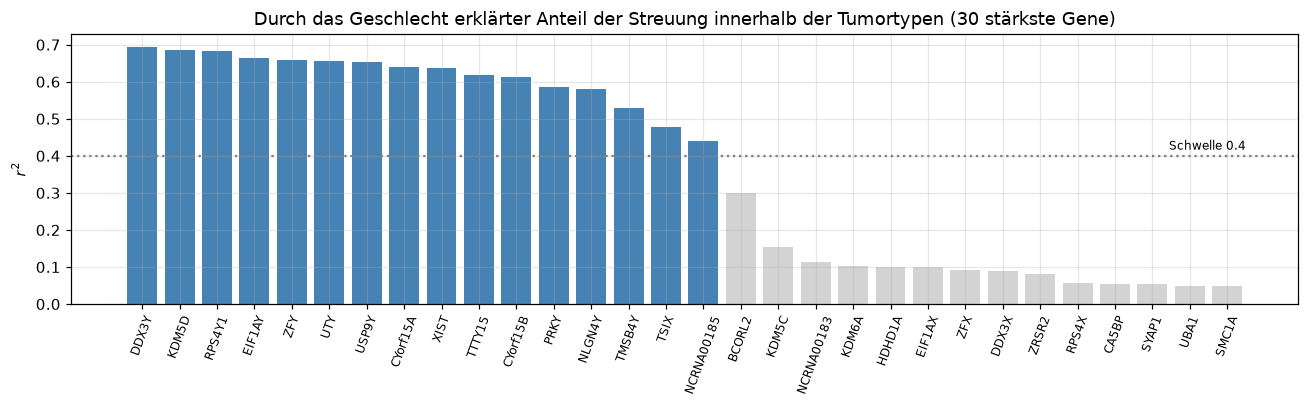

16 Geschlechtsgene (r² > 0.4): DDX3Y, KDM5D, RPS4Y1, EIF1AY, ZFY, UTY, USP9Y, CYorf15A, XIST, TTTY15, CYorf15B, PRKY, NLGN4Y, TMSB4Y, TSIX, NCRNA00185


In [10]:
Xa, meta_a, genes_a, _ = aufbereiten(**{**STANDARD, "k_gene": None})    # alle Gene nach dem Expressionsfilter
beide = meta_a.groupby("study")["gender"].nunique()
m = (meta_a["study"].isin(beide[beide == 2].index) & meta_a["gender"].notna()).to_numpy()
R = Xa[m] - pd.DataFrame(Xa[m]).groupby(meta_a.loc[m, "study"].to_numpy()).transform("mean").to_numpy()
w = (meta_a.loc[m, "gender"] == "weiblich").to_numpy().astype(float)
w -= w.mean()
r2 = ((w @ R) / np.sqrt((w**2).sum() * (R.astype(np.float64) ** 2).sum(axis=0))) ** 2
del Xa, R

r2_sorted = pd.Series(r2, index=genes_a["name"]).sort_values(ascending=False)
SCHWELLE_GESCHLECHT = 0.4
GESCHLECHTSGENE = r2_sorted.index[r2_sorted > SCHWELLE_GESCHLECHT].tolist()

fig, ax = plt.subplots(figsize=(12, 3.8))
top = r2_sorted.head(30)
ax.bar(range(len(top)), top.to_numpy(), color=np.where(top.to_numpy() > SCHWELLE_GESCHLECHT, "steelblue", "lightgray"), width=0.8)
ax.axhline(SCHWELLE_GESCHLECHT, color="gray", ls=":")
ax.annotate(f"Schwelle {SCHWELLE_GESCHLECHT}", (len(top) - 0.5, SCHWELLE_GESCHLECHT), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8)
ax.set_xticks(range(len(top)), top.index, rotation=70, fontsize=8)
ax.set(title="Durch das Geschlecht erklärter Anteil der Streuung innerhalb der Tumortypen (30 stärkste Gene)", ylabel="$r^2$")
plt.tight_layout()
plt.show()
print(f"{len(GESCHLECHTSGENE)} Geschlechtsgene (r² > {SCHWELLE_GESCHLECHT}):", ", ".join(GESCHLECHTSGENE))

**Beobachtung:** 16 Gene liegen deutlich über allen anderen ($r^2$ zwischen 0,44 und 0,69). Danach folgt eine Lücke: `BCORL2` mit 0,30, alle weiteren unter 0,16.
Die Schwelle 0,4 liegt in dieser Lücke; das Ergebnis hängt also nicht empfindlich von ihr ab.

- 13 der 16 Gene liegen auf dem **Y-Chromosom** (`DDX3Y`, `KDM5D`, `RPS4Y1`, `EIF1AY`, `ZFY`, `UTY`, `USP9Y`, `CYorf15A`, `CYorf15B`, `TTTY15`, `PRKY`, `NLGN4Y`, `TMSB4Y`).
- Dazu kommen `XIST` und `TSIX` (X-Inaktivierung) und die nicht codierende RNA `NCRNA00185`.
- Die X-chromosomalen Partner der Y-Gene (`KDM5C`, `DDX3X`, `EIF1AX`, `ZFX`) unterscheiden sich zwischen den Geschlechtern nur schwach ($r^2 \le 0{,}15$) und bleiben erhalten.

Damit ist D3 umgesetzt, ohne dass wir eine zusätzliche Tabelle mit Chromosomen brauchen.

## 5. Der Standardlauf

Mit der Liste der Geschlechtsgene sind alle Parameter festgelegt. Das Protokoll zeigt, wie viele Proben und Gene nach jedem Schritt übrig bleiben.

In [11]:
PARAMETER = {**STANDARD, "entferne_gene": tuple(GESCHLECHTSGENE)}
Xc, meta, genes, protokoll = aufbereiten(**PARAMETER)
n, p = Xc.shape
print(f"Ergebnis: {n} Proben × {p} Gene, {Xc.nbytes / 1e6:.0f} Megabyte")
protokoll

Ergebnis: 9104 Proben × 5000 Gene, 182 Megabyte


,Proben,Gene
Schritt,,
alle Proben,11069,20531
A1 nur Primärtumoren,9879,20531
A3 ohne Do_not_use,9724,20531
A4 nur Illumina HiSeq,9107,20531
A2 eine Probe pro Patient,9104,20531
B1 Gene mit fehlenden Werten entfernt,9104,16711
D1 Expressionsfilter,9104,16709
D3 Geschlechtsgene entfernt,9104,16693
D2 5000 Gene mit größter Varianz,9104,5000


In [12]:
Z, Vt, ev = pca(Xc)
cum = np.cumsum(ev)
print("Erklärte Varianz, kumuliert:", {k: f"{cum[k - 1]:.1%}" for k in [1, 2, 5, 10, 20, 50, 100]})
study = meta["study"].to_numpy()
anteil_std = nachbarn_gleicher_typ(Z, meta)
print(f"Anteil der Nachbarn aus demselben Tumortyp: im Mittel {anteil_std.mean():.1%}")

Erklärte Varianz, kumuliert: {1: '15.2%', 2: '23.3%', 5: '39.3%', 10: '53.1%', 20: '63.8%', 50: '72.7%', 100: '77.4%'}


Anteil der Nachbarn aus demselben Tumortyp: im Mittel 84.1%


**Beobachtungen:**
- Von 11.069 Proben bleiben **9.104**, von 20.531 Genen **5.000**. Die meisten Gene fallen erst durch die Auswahl nach Varianz weg (D2).
  Der Expressionsfilter (D1) entfernt kaum noch etwas (2 Gene), weil die schwach exprimierten Gene überwiegend schon wegen fehlender Werte (B1) weggefallen sind.
- Die ersten 10 Hauptkomponenten erklären 53 % der Varianz, die ersten 50 rund 73 %. Im ersten Durchlauf mit allen 16.711 Genen waren es 50 % bzw. 70 %:
  Durch die Auswahl der 5.000 Gene mit der größten Varianz steckt etwas mehr Struktur in den ersten Achsen.
- Im Mittel stammen 84 % der Nachbarn aus demselben Tumortyp, praktisch so viel wie im ersten Durchlauf (85 %). Die Aufbereitung verändert das Gesamtbild also nicht.

## 6. Prüfung: fehlende Werte (B1)

Im Standardlauf entfernen wir alle Gene, die in mindestens einer der ausgewählten Proben einen fehlenden Wert haben.
Vorschlag war, danach zu prüfen, wie viele dieser Gene **ohne** fehlende Werte unsere Filter bestanden hätten, also wichtig gewesen wären.

In [13]:
X_sel = X_all[meta_all.index[meta_all["barcode"].isin(meta["barcode"])]]       # gleiche Proben wie im Standardlauf (gleiche Reihenfolge)
nan_gen = np.isnan(X_sel).any(axis=0)
Ln = np.log2(np.clip(X_sel[:, nan_gen], 0, None) + 1)                           # fehlende Werte bleiben fehlend
anteil_n = pd.DataFrame(np.where(np.isnan(Ln), np.nan, Ln > 0)).groupby(study).mean().max(axis=0).to_numpy()
var_n = np.nanvar(Ln, axis=0)
var_alle = np.var(aufbereiten(**{**PARAMETER, "k_gene": None})[0], axis=0)
schwelle_k = np.sort(var_alle)[::-1][PARAMETER["k_gene"] - 1]                   # Varianz des k-ten Gens
wichtig = (anteil_n >= PARAMETER["min_anteil_exprimiert"]) & (var_n >= schwelle_k)
namen_n = genes_all.loc[nan_gen, "name"].to_numpy()
print(f"Gene mit fehlenden Werten: {nan_gen.sum()}")
print(f"  davon bestehen den Expressionsfilter: {(anteil_n >= PARAMETER['min_anteil_exprimiert']).sum()}")
print(f"  davon wären unter den {PARAMETER['k_gene']} Genen mit größter Varianz: {wichtig.sum()}")
print("  Beispiele (größte Varianz zuerst):", ", ".join(namen_n[wichtig][np.argsort(var_n[wichtig])[::-1][:15]]))

F = pd.DataFrame(np.isnan(X_sel[:, nan_gen])).groupby(study).mean()
F = F.loc[F.sum(axis=1) > 0]
print("\nIn welchen Tumortypen fehlen die Werte? Anteil der Gene mit fehlenden Werten, bei denen ...")
pd.DataFrame({"alle Proben des Typs fehlen": (F == 1).mean(axis=1), "ein Teil der Proben fehlt": ((F > 0) & (F < 1)).mean(axis=1),
              "Proben des Typs": pd.Series(study).value_counts().loc[F.index]}).round(3)

Gene mit fehlenden Werten: 3820
  davon bestehen den Expressionsfilter: 2739
  davon wären unter den 5000 Genen mit größter Varianz: 1463
  Beispiele (größte Varianz zuerst): KRT5, KRT6A, KRT14, CEACAM5, KRT6B, KRT16, DSG3, KRT6C, CALML3, SERPINB5, HMGCS2, UGT1A6, KRT19, KRT15, AZGP1

In welchen Tumortypen fehlen die Werte? Anteil der Gene mit fehlenden Werten, bei denen ...


,alle Proben des Typs fehlen,ein Teil der Proben fehlt,Proben des Typs
ESCA,0.381,0.000,182
LAML,0.986,0.000,173
OV,0.381,0.000,269
PRAD,0.000,0.378,493
STAD,0.381,0.605,401


**Beobachtungen:** Die Prüfung ergibt ein anderes Bild als erwartet:
- **1.463 der 3.820 entfernten Gene** hätten ohne fehlende Werte zu den 5.000 Genen mit der größten Varianz gehört. Darunter sind genau die Markergene der
  Plattenepithelkarzinome (die Keratine `KRT5`, `KRT6A`, `KRT14`, `KRT16`, dazu `DSG3`, Desmoglein 3) und des Darms (`CEACAM5`, karzinoembryonales Antigen).
- In unserer Auswahl fehlen Werte nur bei 5 Tumortypen. Bei der **akuten myeloischen Leukämie** fehlen für fast alle dieser Gene die Werte **aller** Proben.
  Vermutlich sind diese Gene im Blut überhaupt nicht aktiv, und EB++ (*Empirical Bayes*) konnte für einen Batch ohne jede Streuung keine Korrektur schätzen.
- Speiseröhren-, Magen- und Eierstockkrebs teilen ein gemeinsames Muster (bei 38 % der Gene fehlen alle Proben): Sie stammen aus den beiden Sequenzierzentren `13` und `31`, die EB++ korrigiert hat.
  Beim Prostatakrebs fehlen die Werte nur bei einem Teil der Proben.
- Für die meisten Paare aus Gen und Tumortyp gibt es also **keinen einzigen Wert**. Ein Auffüllen mit Werten desselben Tumortyps ist damit nicht möglich.

Wie stark wirkt sich das aus? Wir vergleichen den Standardlauf mit der Variante „fehlende Werte mit 0 auffüllen“, bei der diese Gene erhalten bleiben.

In [14]:
Xc_null, meta_null, genes_null, _ = aufbereiten(**{**PARAMETER, "nan_regel": "null"})
Z_null, _, _ = pca(Xc_null)
anteil_null = nachbarn_gleicher_typ(Z_null, meta_null)
print(f"Gemeinsame Gene der beiden Varianten: {genes['name'].isin(genes_null['name']).sum()} von {p}")
vergleich = pd.DataFrame({"Gene entfernt (Standard)": anteil_std, "mit 0 aufgefüllt": anteil_null})
betroffen = F.index.tolist()
print("Anteil der Nachbarn aus demselben Tumortyp, Mittel über alle Typen:", vergleich.mean().round(3).to_dict())
vergleich.loc[betroffen].round(3)

Gemeinsame Gene der beiden Varianten: 3749 von 5000
Anteil der Nachbarn aus demselben Tumortyp, Mittel über alle Typen: {'Gene entfernt (Standard)': 0.841, 'mit 0 aufgefüllt': 0.845}


,Gene entfernt (Standard),mit 0 aufgefüllt
ESCA,0.370,0.394
LAML,1.000,1.000
OV,0.954,0.961
PRAD,1.000,1.000
STAD,0.787,0.791


**Beobachtungen:**
- Obwohl rund ein Viertel der Gene ausgetauscht wird (nur 3.749 von 5.000 Genen sind in beiden Varianten), ändert sich die Nachbarschaft **kaum**:
  im Mittel 84,1 % gegenüber 84,5 %, bei den betroffenen Tumortypen höchstens 2,4 Prozentpunkte (Speiseröhrenkrebs).
- Die Unterschiede zwischen Tumortypen stecken also in sehr vielen Genen gleichzeitig; das Fehlen einzelner Markergene schadet nicht.

**Entscheidung:** Standard bleibt **„Gene entfernen“**. Das Auffüllen mit 0 würde für die betroffenen Tumortypen Werte erfinden, ohne das Ergebnis zu verbessern.
Wenn eine spätere Frage gezielt einzelne Markergene wie `KRT5` braucht (zum Beispiel: Wie viel Plattenepithel steckt im Speiseröhrenkrebs?), ist `nan_regel="null"` eine Option.

## 7. Prüfung: Störgrößen und Batch-Effekte (E2)

Für jede der ersten 20 Hauptkomponenten messen wir mit $\eta^2$, wie viel ihrer Streuung erklärt wird durch

- den **Tumortyp** (das erwünschte Signal),
- das **Geschlecht innerhalb der Tumortypen** (sollte nach Abschnitt 4 nahe 0 sein),
- die **Platte innerhalb der Tumortypen**. Weil es viele Platten mit wenigen Proben gibt, erklären Platten schon zufällig etwas. Als Vergleich mischen wir die Platten
  innerhalb jedes Tumortyps zufällig neu („Zufall“). Nur was deutlich darüber liegt, ist ein echter Platteneffekt.

Das **Sequenzierzentrum** lässt sich nur beim Magenkrebs (STAD) prüfen: Er ist der einzige Tumortyp, dessen Proben zu ähnlichen Teilen aus zwei Zentren stammen (`13` und `31`).

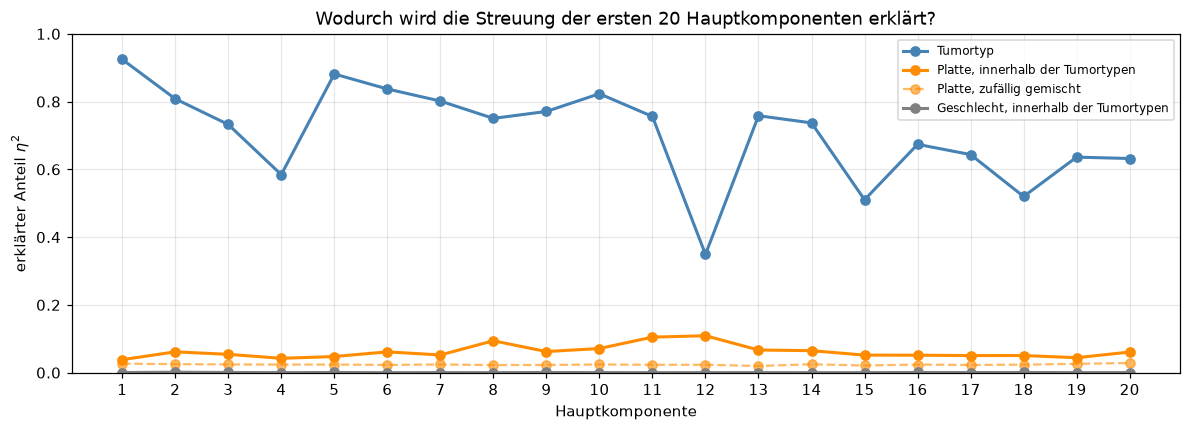

,Varianz,Tumortyp,Geschlecht (innerhalb),Platte (innerhalb),Platte (Zufall),Zentrum (nur Magenkrebs),Platte über Zufall
Hauptkomponente,,,,,,,
1,0.152,0.925,0.000,0.038,0.027,0.008,0.012
2,0.081,0.808,0.001,0.061,0.025,0.020,0.036
3,0.071,0.732,0.000,0.054,0.024,0.027,0.030
4,0.049,0.584,0.000,0.042,0.024,0.060,0.018
5,0.041,0.881,0.000,0.048,0.024,0.021,0.024
6,0.035,0.837,0.000,0.061,0.023,0.081,0.038
7,0.033,0.802,0.000,0.052,0.024,0.023,0.028
8,0.026,0.750,0.000,0.094,0.022,0.006,0.072
9,0.023,0.771,0.000,0.062,0.023,0.000,0.040


In [15]:
rng = np.random.default_rng(SEED)
platte = meta["plate"].to_numpy()
platte_zufall = meta.groupby("study")["plate"].transform(lambda s: rng.permutation(s.to_numpy())).to_numpy()
magen = study == "STAD"
zeilen = []
for j in range(20):
    r = innerhalb(Z[:, j], study)
    zeilen.append({"Hauptkomponente": j + 1, "Varianz": ev[j], "Tumortyp": eta2(Z[:, j], study),
                   "Geschlecht (innerhalb)": eta2(r, meta["gender"]), "Platte (innerhalb)": eta2(r, platte),
                   "Platte (Zufall)": eta2(r, platte_zufall), "Zentrum (nur Magenkrebs)": eta2(Z[magen, j], meta.loc[magen, "center"])})
stoer = pd.DataFrame(zeilen).set_index("Hauptkomponente")
stoer["Platte über Zufall"] = stoer["Platte (innerhalb)"] - stoer["Platte (Zufall)"]

fig, ax = plt.subplots(figsize=(13, 4))
x = stoer.index.to_numpy()
ax.plot(x, stoer["Tumortyp"], marker="o", lw=2, color="steelblue", label="Tumortyp")
ax.plot(x, stoer["Platte (innerhalb)"], marker="o", lw=2, color="darkorange", label="Platte, innerhalb der Tumortypen")
ax.plot(x, stoer["Platte (Zufall)"], marker="o", lw=1.5, ls="--", color="darkorange", alpha=0.6, label="Platte, zufällig gemischt")
ax.plot(x, stoer["Geschlecht (innerhalb)"], marker="o", lw=2, color="gray", label="Geschlecht, innerhalb der Tumortypen")
ax.set_xticks(x)
ax.set(title="Wodurch wird die Streuung der ersten 20 Hauptkomponenten erklärt?", xlabel="Hauptkomponente", ylabel="erklärter Anteil $\\eta^2$", ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()
stoer.round(3)

**Beobachtungen:**
- Der **Tumortyp** erklärt bei fast allen der ersten 20 Hauptkomponenten 50 bis 93 % der Streuung. Die Achsen bilden also überwiegend Unterschiede zwischen Tumortypen ab, wie gewünscht.
- Das **Geschlecht** erklärt innerhalb der Tumortypen auf keiner Achse mehr als 0,1 %. Die Geschlechtsachse aus Abschnitt 4 ist durch das Entfernen der 16 Gene vollständig verschwunden.
- Die **Platte** erklärt auf jeder Achse etwas mehr als der Zufall, aber wenig: 1 bis 9 Prozentpunkte über dem Zufallswert.
  Am stärksten bei den Hauptkomponenten 8, 11 und 12. **Hauptkomponente 12** fällt auf: Der Tumortyp erklärt dort nur 35 %, die Platte 11 % (Zufall 2 %).
  Sie ist ein Kandidat für eine überwiegend technische Achse.
- Beim **Magenkrebs** erklärt das Sequenzierzentrum auf einzelnen Achsen bis zu 8 % (Hauptkomponenten 6 und 13). Zum Vergleich: Bei zwei Gruppen und 400 Proben
  erklärt der Zufall etwa $1/400 \approx 0{,}25\,\%$. Trotz EB++ ist also ein kleiner Rest des Zentrumsunterschieds geblieben.

### 6.1 Platten innerhalb des Brustkrebses

Am deutlichsten lässt sich ein Platteneffekt **innerhalb eines großen Tumortyps** sehen, weil dort der Tumortyp als Erklärung wegfällt.
Wir rechnen eine eigene Hauptkomponentenanalyse nur für Brustkrebs (BRCA) und messen für jede Achse, wie viel die Platte erklärt.

In [16]:
b = study == "BRCA"
Zb, Vb, evb = pca(Xc[b] - Xc[b].mean(axis=0), k=10)
pl_b = platte[b]
pl_b_zufall = rng.permutation(pl_b)
tss_b = meta.loc[b, "tss"].to_numpy()
brca = pd.DataFrame({"Varianz": evb, "Platte": [eta2(Zb[:, j], pl_b) for j in range(10)],
                     "Platte (Zufall)": [eta2(Zb[:, j], pl_b_zufall) for j in range(10)],
                     "Klinik": [eta2(Zb[:, j], tss_b) for j in range(10)]}, index=pd.Index(range(1, 11), name="Hauptkomponente (Brustkrebs)"))
j_pl = int(brca["Platte"].idxmax()) - 1
o = np.argsort(Vb[j_pl])
print(f"Achse mit dem stärksten Platteneffekt: Hauptkomponente {j_pl + 1} des Brustkrebses ({evb[j_pl]:.1%} der Varianz innerhalb Brustkrebs)")
print("  Ende +:", ", ".join(genes["name"].to_numpy()[o[::-1][:12]]))
print("  Ende −:", ", ".join(genes["name"].to_numpy()[o[:12]]))
brca.round(3)

Achse mit dem stärksten Platteneffekt: Hauptkomponente 3 des Brustkrebses (4.5% der Varianz innerhalb Brustkrebs)
  Ende +: SOX10, C2orf82, MIA, SCGB3A1, KRT17, PPP1R14A, SYCE1L, PRSS50, S100A1, TF, SLC16A11, GPT
  Ende −: COL11A1, EDIL3, CDKL5, PLXNC1, IL6ST, PRR11, BICC1, PRKG1, UHMK1, KIAA0754, KIAA1199, SERINC5


,Varianz,Platte,Platte (Zufall),Klinik
Hauptkomponente (Brustkrebs),,,,
1,0.128,0.068,0.040,0.041
2,0.102,0.095,0.028,0.089
3,0.045,0.488,0.033,0.276
4,0.043,0.049,0.038,0.083
5,0.031,0.096,0.046,0.073
6,0.024,0.048,0.039,0.035
7,0.020,0.044,0.036,0.057
8,0.016,0.056,0.037,0.057
9,0.015,0.068,0.028,0.059


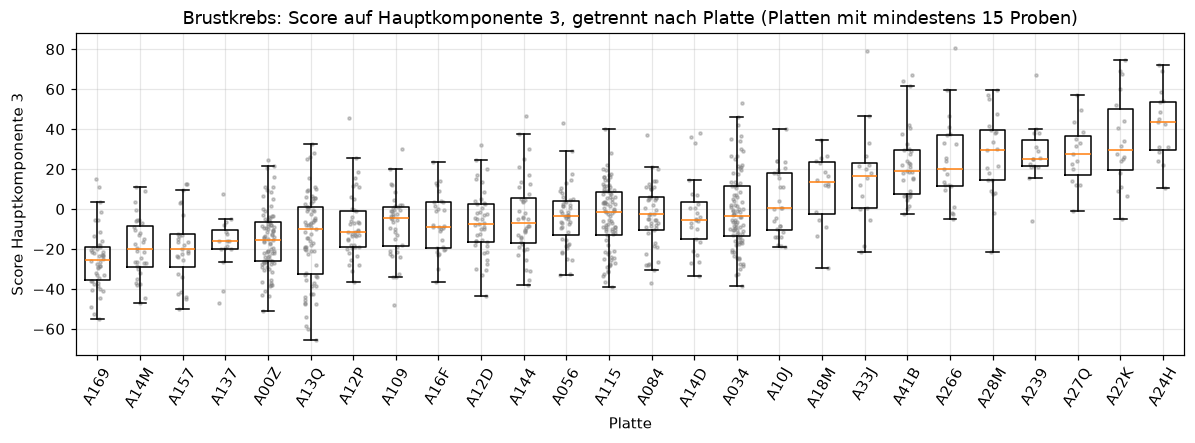

In [17]:
mittel = pd.Series(Zb[:, j_pl]).groupby(pl_b).agg(["mean", "size"])
gross = mittel[mittel["size"] >= 15].sort_values("mean")
fig, ax = plt.subplots(figsize=(13, 3.8))
data = [Zb[pl_b == q, j_pl] for q in gross.index]
ax.boxplot(data, tick_labels=gross.index, showfliers=False, widths=0.6)
for i, d in enumerate(data):
    ax.scatter(np.full(len(d), i + 1) + rng.uniform(-0.15, 0.15, len(d)), d, s=4, alpha=0.4, color="gray")
ax.set(title=f"Brustkrebs: Score auf Hauptkomponente {j_pl + 1}, getrennt nach Platte (Platten mit mindestens 15 Proben)",
       xlabel="Platte", ylabel=f"Score Hauptkomponente {j_pl + 1}")
ax.tick_params(axis="x", rotation=60)
plt.show()

**Beobachtungen:**
- Innerhalb des Brustkrebses gibt es eine deutliche **Plattenachse**: Hauptkomponente 3 (4,5 % der Varianz innerhalb des Brustkrebses) wird zu **49 %** durch die Platte erklärt
  (Zufall 3 %) und zu 28 % durch die Klinik, die das Gewebe geliefert hat.
- Im Bild verschieben sich die Platten schrittweise. Die Platten mit den höchsten Werten tragen meist Nummern ab `A2…`, die mit den niedrigsten `A0…` und `A1…`.
  Die Plattennummern wurden fortlaufend vergeben; die Achse könnte also mit dem **Zeitpunkt der Verarbeitung** zusammenhängen (Vermutung, nicht geprüft).
- Am negativen Ende stehen Gene ohne erkennbare gemeinsame Gewebefunktion (`PRR11`, `UHMK1`, `KIAA0754`, `CDKL5`), am positiven Ende gemischte Gewebegene (`SOX10`, `MIA`, `KRT17`).
  Ob das Technik ist oder ob die Platten mit Untergruppen des Brustkrebses zusammenfallen (etwa weil Kliniken zu verschiedenen Zeiten verschiedene Patientinnen geliefert haben),
  lässt sich hier nicht entscheiden.

Gibt es dieselbe Achse auch in der gemeinsamen Hauptkomponentenanalyse aller Tumortypen? Wir vergleichen die Ladungen der Plattenachse des Brustkrebses
mit den Ladungen der ersten 20 gemeinsamen Hauptkomponenten (Kosinus der Winkel zwischen den Ladungsvektoren; 1 = gleiche Richtung).

In [18]:
kos = np.abs(Vt[:20] @ Vb[j_pl])
j_glob = int(np.argmax(kos))
print("Ähnlichkeit zur Plattenachse des Brustkrebses:", {j + 1: round(float(c), 2) for j, c in enumerate(kos) if c > 0.2})
print(f"Am ähnlichsten: Hauptkomponente {j_glob + 1} ({ev[j_glob]:.1%} der Varianz) | "
      f"Tumortyp erklärt {stoer.loc[j_glob + 1, 'Tumortyp']:.0%}, Platte innerhalb der Typen {stoer.loc[j_glob + 1, 'Platte (innerhalb)']:.0%} "
      f"(Zufall {stoer.loc[j_glob + 1, 'Platte (Zufall)']:.0%})")

Ähnlichkeit zur Plattenachse des Brustkrebses: {4: 0.2, 8: 0.41, 10: 0.22, 11: 0.35, 12: 0.4, 20: 0.22}
Am ähnlichsten: Hauptkomponente 8 (2.6% der Varianz) | Tumortyp erklärt 75%, Platte innerhalb der Typen 9% (Zufall 2%)


**Beobachtung:** In der gemeinsamen Hauptkomponentenanalyse taucht die Plattenachse nicht als eigene Achse auf, sondern **verteilt auf die Hauptkomponenten 8, 11 und 12**
(Kosinus 0,35 bis 0,41). Das sind genau die Achsen, auf denen auch die Platte innerhalb der Tumortypen am meisten erklärt (9 bis 11 %).

**Entscheidung:** Wir korrigieren nicht zusätzlich nach Platte (E1), weil Platten mit dem Tumortyp vermengt sind und eine Korrektur echte Unterschiede mit entfernen würde.
Aber: Ab etwa Hauptkomponente 8 enthalten die Achsen einen spürbaren Plattenanteil. Wenn später ein Cluster auffällig aussieht, prüfen wir zuerst die Platten.

## 8. Prüfung: Proben vom älteren Illumina Genome Analyzer (A4)

Im Standardlauf fehlen die 598 Proben vom älteren Gerät (nur Endometriumkarzinom, Dickdarm- und Mastdarmkrebs). Hat die Batch-Korrektur den Geräteunterschied ausgeglichen?
Wir rechnen die Aufbereitung **mit** diesen Proben und fragen innerhalb der drei Tumortypen: Liegen Proben vom älteren Gerät bevorzugt neben Proben vom älteren Gerät?

Wäre der Geräteunterschied vollständig ausgeglichen, entspräche der Anteil der Nachbarn vom älteren Gerät ungefähr dem Anteil dieser Proben im Tumortyp,
egal von welchem Gerät die Probe selbst stammt.

In [19]:
Xc_ga, meta_ga, genes_ga, prot_ga = aufbereiten(**{**PARAMETER, "nur_hiseq": False})
Z_ga, _, _ = pca(Xc_ga)
st_ga = meta_ga["study"].to_numpy()
ga = (meta_ga["platform"] == "GA").to_numpy()
nb_ga = nachbarn(Z_ga[:, :50])
zeilen = []
for s in ["UCEC", "COAD", "READ"]:
    m = st_ga == s
    gleich = st_ga[nb_ga[m]] == s                      # nur Nachbarn aus demselben Tumortyp betrachten
    ga_nb = ga[nb_ga[m]]
    zeilen.append({"Tumortyp": s, "Proben": m.sum(), "Anteil älteres Gerät": ga[m].mean(),
                   "Nachbarn vom älteren Gerät, wenn Probe vom älteren Gerät": (ga_nb & gleich)[ga[m]].sum() / gleich[ga[m]].sum(),
                   "Nachbarn vom älteren Gerät, wenn Probe vom HiSeq": (ga_nb & gleich)[~ga[m]].sum() / gleich[~ga[m]].sum()})
print(f"Mit dem älteren Gerät: {len(meta_ga)} Proben, {Xc_ga.shape[1]} Gene (es fallen mehr Gene wegen fehlender Werte weg)")
pd.DataFrame(zeilen).set_index("Tumortyp").round(2)

Mit dem älteren Gerät: 9720 Proben, 5000 Gene (es fallen mehr Gene wegen fehlender Werte weg)


,Proben,Anteil älteres Gerät,"Nachbarn vom älteren Gerät, wenn Probe vom älteren Gerät","Nachbarn vom älteren Gerät, wenn Probe vom HiSeq"
Tumortyp,,,,
UCEC,528,0.67,0.81,0.64
COAD,441,0.37,0.60,0.31
READ,156,0.42,0.69,0.33


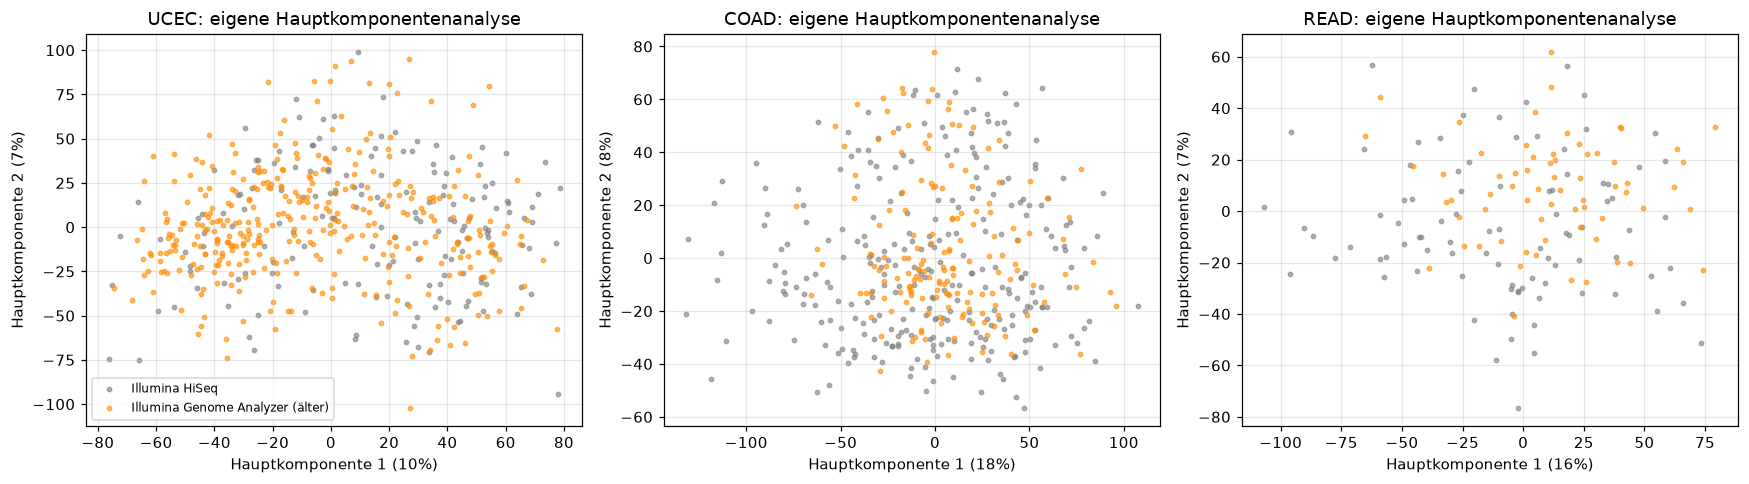

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, s in zip(axes, ["UCEC", "COAD", "READ"]):
    m = st_ga == s
    Zs, _, evs = pca(Xc_ga[m] - Xc_ga[m].mean(axis=0), k=5)
    for maske, farbe, name in [(~ga[m], "gray", "Illumina HiSeq"), (ga[m], "darkorange", "Illumina Genome Analyzer (älter)")]:
        ax.scatter(Zs[maske, 0], Zs[maske, 1], s=8, alpha=0.6, color=farbe, label=name)
    ax.set(title=f"{s}: eigene Hauptkomponentenanalyse", xlabel=f"Hauptkomponente 1 ({evs[0]:.0%})", ylabel=f"Hauptkomponente 2 ({evs[1]:.0%})")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Beobachtungen:**
- Der Geräteunterschied ist **nicht vollständig ausgeglichen**. In allen drei Tumortypen liegen Proben vom älteren Gerät bevorzugt neben Proben vom älteren Gerät:
  beim Endometriumkarzinom 81 % (gegenüber 64 % bei HiSeq-Proben), beim Dickdarmkrebs 60 % (gegenüber 31 %), beim Mastdarmkrebs 69 % (gegenüber 33 %).
- In den Bildern überlappen beide Gruppen stark, sind aber gegeneinander verschoben, am deutlichsten beim Endometriumkarzinom.

**Entscheidung:** Wir bleiben bei **„nur Illumina HiSeq“**. Der Preis: Statt 528 bleiben 173 Proben vom Endometriumkarzinom, statt 441 bleiben 278 vom Dickdarmkrebs
und statt 156 bleiben 90 vom Mastdarmkrebs. Für eine Robustheitsprüfung reicht `nur_hiseq=False`.

## 9. Prüfung: auffällige Proben (A5) und ausgeglichene Stichprobe (A7)

### 8.1 Auffällige Proben

Zwei Arten von Kandidaten für einen Qualitätsfilter:
- das 1 % der Proben mit dem höchsten Anteil an Nullen (möglicherweise schlechte RNA-Qualität),
- Proben, bei denen die Expression von `XIST` und `RPS4Y1` (ribosomales Protein S4 vom Y-Chromosom) dem Geschlecht laut klinischer Tabelle widerspricht (mögliche Verwechslung).

Liegen sie in der Hauptkomponentenanalyse bei ihrem eigenen Tumortyp? Dann sind sie für unsere Frage unauffällig.

In [21]:
nb = nachbarn(Z[:, :50])
eigener = (study[nb] == study[:, None]).mean(axis=1)
nullen = meta["zero_frac"].to_numpy()
viele_nullen = nullen >= np.quantile(nullen, 0.99)
xist = np.log2(np.clip(X_sel[:, genes_all.index[genes_all["name"] == "XIST"][0]], 0, None) + 1)
y1 = np.log2(np.clip(X_sel[:, genes_all.index[genes_all["name"] == "RPS4Y1"][0]], 0, None) + 1)
g = meta["gender"].to_numpy()
widerspruch = ((g == "weiblich") & (y1 > 5) & (xist < 8)) | ((g == "männlich") & (y1 < 5) & (xist > 8))
pd.DataFrame({"Proben": [viele_nullen.sum(), widerspruch.sum(), n],
              "Anteil Nachbarn eigener Tumortyp": [eigener[viele_nullen].mean(), eigener[widerspruch].mean(), eigener.mean()]},
             index=[f"1 % mit den meisten Nullen (≥ {np.quantile(nullen, 0.99):.0%} Nullen)", "Geschlecht widersprüchlich", "alle Proben"]).round(2)

,Proben,Anteil Nachbarn eigener Tumortyp
1 % mit den meisten Nullen (≥ 21% Nullen),92,0.94
Geschlecht widersprüchlich,12,0.90
alle Proben,9104,0.88


**Beobachtung:** Beide Gruppen liegen sogar etwas häufiger bei ihrem eigenen Tumortyp als der Durchschnitt (94 % bzw. 90 % gegenüber 88 %).
(Hier wird über Proben gemittelt, oben über Tumortypen; deshalb 88 % statt 84 %.)

**Entscheidung:** kein zusätzlicher Qualitätsfilter. Der Geschlechtswiderspruch spielt nach dem Entfernen der Geschlechtsgene ohnehin keine Rolle mehr.

### 8.2 Ausgeglichene Stichprobe

Große Tumortypen könnten die Achsen der Hauptkomponentenanalyse prägen. Zum Vergleich berechnen wir die Achsen nur aus einer Stichprobe mit **höchstens 150 Proben pro Tumortyp**,
projizieren dann **alle** Proben auf diese Achsen und vergleichen den Anteil der Nachbarn aus demselben Tumortyp.

In [22]:
_, meta_bal, _, _ = aufbereiten(**{**PARAMETER, "max_pro_typ": 150})
in_stichprobe = meta["barcode"].isin(meta_bal["barcode"]).to_numpy()
mu_bal = Xc[in_stichprobe].mean(axis=0)
_, Vt_bal, _ = pca(Xc[in_stichprobe] - mu_bal, k=50)
Z_bal = (Xc - mu_bal) @ Vt_bal.T
anteil_bal = nachbarn_gleicher_typ(Z_bal, meta)
cmp = pd.DataFrame({"Standard": anteil_std, "Achsen aus ausgeglichener Stichprobe": anteil_bal, "Proben": pd.Series(study).value_counts()})
cmp["Differenz"] = cmp["Achsen aus ausgeglichener Stichprobe"] - cmp["Standard"]
print(f"Stichprobe: {in_stichprobe.sum()} Proben | Mittel Standard {anteil_std.mean():.3f}, ausgeglichen {anteil_bal.mean():.3f} | "
      f"größte Änderung: {cmp['Differenz'].abs().max():.3f}")
cmp.sort_values("Proben").head(8).round(3)

Stichprobe: 4213 Proben | Mittel Standard 0.841, ausgeglichen 0.841 | größte Änderung: 0.016


,Standard,Achsen aus ausgeglichener Stichprobe,Proben,Differenz
CHOL,0.524,0.522,36,-0.002
DLBC,0.986,0.986,48,0.000
UCS,0.532,0.549,57,0.016
KICH,0.808,0.808,65,0.000
ACC,0.963,0.962,78,-0.001
UVM,0.988,0.989,80,0.001
MESO,0.909,0.908,87,-0.001
READ,0.290,0.281,90,-0.010


**Beobachtung:** Praktisch kein Unterschied: Das Mittel ist identisch, die größte Änderung beträgt 1,6 Prozentpunkte (Karzinosarkom der Gebärmutter).
Die großen Tumortypen verzerren die Achsen für unsere Frage also nicht.

**Entscheidung:** kein Ausgleich der Gruppengrößen bei der Aufbereitung. Beim Clustering kann die Frage wieder auftauchen, weil viele Verfahren gleich große Cluster bevorzugen.

## 10. Speichern

Wir speichern die fertige Matrix und alles, was dazugehört, in `data/pancanatlas/`:

| Datei | Inhalt |
|---|---|
| `aufbereitet_matrix.npy` | Proben $\times$ Gene, $\log_2(x+1)$, zentriert, `float32` (32-Bit-Gleitkommazahlen) |
| `aufbereitet_proben.csv` | Metadaten der Proben in Zeilenreihenfolge |
| `aufbereitet_gene.csv` | Gene in Spaltenreihenfolge (Name, Symbol, Entrez-Nummer und Kennzahlen) |
| `aufbereitet_parameter.json` | Parameter der Aufbereitung und Protokoll |

Die Hauptkomponenten speichert erst `notebook_pca.ipynb`; die Hauptkomponentenanalysen hier dienen nur den Prüfungen.

In [23]:
np.save(DATA_DIR / "aufbereitet_matrix.npy", Xc)
meta.to_csv(DATA_DIR / "aufbereitet_proben.csv", index=False)
genes.to_csv(DATA_DIR / "aufbereitet_gene.csv", index=False)
info = {"parameter": {k: (list(v) if isinstance(v, tuple) else v) for k, v in PARAMETER.items()},
        "schwelle_geschlechtsgene_r2": SCHWELLE_GESCHLECHT,
        "protokoll": protokoll.reset_index().to_dict(orient="records")}
(DATA_DIR / "aufbereitet_parameter.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=int))
print(f"Gespeichert: {n} Proben × {p} Gene")

Gespeichert: 9104 Proben × 5000 Gene


Laden in einem späteren Notebook:
```python
X = np.load("data/pancanatlas/aufbereitet_matrix.npy")              # Proben × Gene, log2(x+1), zentriert
meta = pd.read_csv("data/pancanatlas/aufbereitet_proben.csv", dtype={"sample_type": str, "center": str, "portion": str})
genes = pd.read_csv("data/pancanatlas/aufbereitet_gene.csv")
```

## 11. Zusammenfassung

Die fertige Matrix hat **9.104 Proben (Primärtumoren) $\times$ 5.000 Gene**, logarithmiert und zentriert. Umgesetzt und geprüft:

| Entscheidung | Umsetzung | Ergebnis der Prüfung |
|---|---|---|
| A1 Probentypen | nur Primärtumoren | – |
| A2 eine Probe pro Patient | erste nach Barcode (betrifft 3 Proben) | – |
| A3 `Do_not_use` | entfernt | – |
| A4 Sequenziergerät | nur Illumina HiSeq | Proben vom älteren Gerät bilden innerhalb ihrer Tumortypen eigene Nachbarschaften → Entfernen bestätigt |
| A5 Qualitätsfilter | keiner | Proben mit vielen Nullen oder Geschlechtswiderspruch liegen bei ihrem Tumortyp → kein Filter nötig |
| A6 Tumortypen | alle 33 | – |
| A7 Gruppengrößen | kein Ausgleich | Achsen aus ausgeglichener Stichprobe ändern nichts → kein Ausgleich nötig |
| B1 fehlende Werte | Gene entfernen | entfernt 1.463 eigentlich wichtige Gene, darunter Keratine; Auffüllen mit 0 ändert das Ergebnis aber nicht → beibehalten |
| B2 negative Werte | auf 0 | – |
| C1 Transformation | $\log_2(x+1)$ | – |
| C3, C4 | zentrieren, nicht standardisieren | – |
| D1 Expressionsfilter | in mindestens einem Tumortyp bei mindestens der Hälfte der Proben $> 0$ | entfernt nach B1 kaum noch etwas |
| D2 Genauswahl | 5.000 Gene mit größter Varianz | – |
| D3 Geschlechtsgene | 16 Gene entfernt, aus den Daten bestimmt | vorher Geschlechtsachse auf Hauptkomponente 9, danach keine mehr |
| E1 zusätzliche Batch-Korrektur | keine | – |
| E2 Störgrößen | geprüft | kleiner Platteneffekt ab Hauptkomponente 8, deutlich innerhalb des Brustkrebses; kleiner Rest-Zentrumseffekt beim Magenkrebs |

**Worauf wir später achten müssen:**
- Ab etwa Hauptkomponente 8 enthalten die Achsen einen Plattenanteil. Auffällige Cluster zuerst nach Platte einfärben.
- Bei Aufspaltungen innerhalb eines Tumortyps (vor allem Brustkrebs) ist die Platte eine mögliche Erklärung.
- Wer mehr Endometriumkarzinome, Dick- und Mastdarmkrebs braucht, kann `nur_hiseq=False` setzen, muss dann aber mit einem Geräteunterschied rechnen.

Nicht geprüft haben wir bisher C4 (Standardisieren), D2 mit anderem $k$ und F1 (Zahl der Hauptkomponenten). Diese Vergleiche gehören zu den Methoden-Notebooks;
dort reicht es, die Parameter der Funktion `aufbereiten` zu ändern.